In [1]:
# file to analze energy spectrum and wavefunctions for different disorder simplified model## 

In [2]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
from Minimal_Model_2D import *
import time

np.set_printoptions(threshold=sys.maxsize)

In [3]:
class Minimal_Model_Subband_Basis(twoD_Minimal_Model):

    def Ham(self, dis_mag=0, uncorr_var=1, lmbda=0, seed=None, kx=0, ky=0, phi=0):

        M = bmat([
           [self.H_same_spin(dis_mag, uncorr_var, lmbda, seed, kx, ky ), self.Del_array(phi) ],
           [self.Del_array(phi).conjugate(),-self.H_same_spin(dis_mag, uncorr_var, lmbda, seed, -kx, -ky).conjugate() ]
       ]) 

        return M
    
    def U_dag_ph(self, my=1):

        M = bmat([
            [ self.U_dag(my), None],
            [None, -self.U_dag(my).conjugate()],
        ])

        return M
    
    def Ham_changed_basis(self,  dis_mag=0, uncorr_var=1, lmbda=0, seed=None, kx=0, ky=0, phi=0, my=1):

        S_dag = self.U_dag_ph(my)

        S = self.U_dag_ph(my).transpose().conjugate()

        H = self.Ham(dis_mag, uncorr_var, lmbda, seed, kx, ky,phi)

        return S_dag.dot(H).dot(S)

In [4]:
NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized InAs
MEFF_SM = 0.023     # InAs
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
#ALPHAT = 400        # meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 8           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC


print(OMEGA/2, 3*OMEGA/2)

MU_SC =   OMEGA/2 +OMEGA/10  # in between two subbands - such that we get two abs prferably 
MU_SM =   OMEGA/2 +OMEGA/10  # in between two subbands - such that we get two abs prferably

print(MU_SM)

UNCORR_VAR = 1167  ### uncorrelated variance of disorder

#LMBDA = np.array([0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1,1])
#LMBDA = np.linspace(0.075, 0.2, 51)
#LMBDA = np.linspace(0.15, 0.21, 81)
LMBDA=0
#SEED = 42  ## seed for the disorder 
SEED = 58  ## seed for the disorder

A = Minimal_Model_Subband_Basis(NTOT,NSM,NSC,M,AX,AY,OMEGA, delta=DELTA, meff_sc=MEFF_SC, meff_sm=MEFF_SM, mu_sm = MU_SM, mu_sc=MU_SC)
H = A.Ham(phi=PHI)
E= eigsh(H ,k=K_NUM ,sigma=0, return_eigenvectors=False)

#sorted_index = np.argsort(E)

Esorted = np.sort(E)/DELTA
#Vsorted = V[:,sorted_index]

print(Esorted)

0.6631720133634798 1.9895160400904393
0.7958064160361757
[-1.00258074 -1.00244524 -0.78989741 -0.25907115  0.25907115  0.78989741
  1.00244524  1.00258074]


In [5]:
#LMBDA = np.linspace(0.075, 0.2, 51)

NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized InAs
MEFF_SM = 0.023     # InAs
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
#ALPHAT = 400        # meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 8           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print(OMEGA/2, 3*OMEGA/2)

MU_SC =   OMEGA/2 +OMEGA/10  # in between two subbands - such that we get two abs prferably 
MU_SM =   OMEGA/2 +OMEGA/10  # in between two subbands - such that we get two abs prferably

print(MU_SM)


UNCORR_VAR = 1167  ### uncorrelated variance of disorder

#LMBDA = np.array([0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1,1])
LMBDA = np.linspace(0.0, 0.25, 81)
#LMBDA = np.linspace(0.15, 0.21, 81)
#LMBDA=0
#SEED = 42  ## seed for the disorder
#  
SEED = 58 

Ep = np.empty((LMBDA.shape[0],K_NUM))

for i in range(LMBDA.shape[0]):

    t1 = time.time()

    
    A = Minimal_Model_Subband_Basis(NTOT,NSM,NSC,M,AX,AY,OMEGA, delta=DELTA, meff_sc=MEFF_SC, meff_sm=MEFF_SM, mu_sm = MU_SM, mu_sc=MU_SC)
    H = A.Ham(uncorr_var=UNCORR_VAR, lmbda=LMBDA[i], seed=SEED, phi=PHI)
    E = eigsh(H ,k=K_NUM ,sigma=0, return_eigenvectors=False)

    Esorted = np.sort(E)

    Ep[i,:] = Esorted/DELTA

    t2 = time.time()

    print("sample no. {}".format(i), "time: ", round(t2-t1), "lmbda: ", LMBDA[i])

    #print(Ep[i,:])


np.save('Ep_no_soc_one_spin_vs_lmbda_{:.2f}_to_{:.2f}_mu_{:.2f}.npy'.format(LMBDA[0],LMBDA[-1],MU_SC),Ep)

0.6631720133634798 1.9895160400904393
0.7958064160361757
sample no. 0 time:  69 lmbda:  0.0
sample no. 1 time:  73 lmbda:  0.003125
sample no. 2 time:  75 lmbda:  0.00625
sample no. 3 time:  74 lmbda:  0.009375000000000001
sample no. 4 time:  72 lmbda:  0.0125
sample no. 5 time:  72 lmbda:  0.015625
sample no. 6 time:  67 lmbda:  0.018750000000000003
sample no. 7 time:  68 lmbda:  0.021875000000000002
sample no. 8 time:  65 lmbda:  0.025
sample no. 9 time:  72 lmbda:  0.028125
sample no. 10 time:  66 lmbda:  0.03125
sample no. 11 time:  61 lmbda:  0.034375
sample no. 12 time:  66 lmbda:  0.037500000000000006
sample no. 13 time:  64 lmbda:  0.040625
sample no. 14 time:  64 lmbda:  0.043750000000000004
sample no. 15 time:  64 lmbda:  0.046875
sample no. 16 time:  67 lmbda:  0.05
sample no. 17 time:  74 lmbda:  0.053125000000000006
sample no. 18 time:  75 lmbda:  0.05625
sample no. 19 time:  79 lmbda:  0.059375000000000004
sample no. 20 time:  78 lmbda:  0.0625
sample no. 21 time:  66 lmb

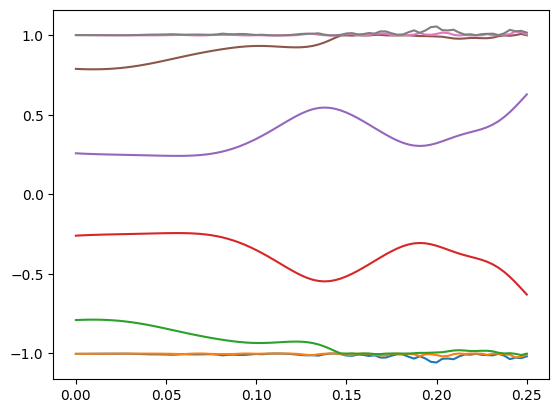

In [6]:
plt.plot(LMBDA, Ep)

plot eigenvalue and eigenfunction at lmbda = 0 

In [40]:
#LMBDA = np.linspace(0.075, 0.2, 51)

NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized InAs
MEFF_SM = 0.023     # InAs
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
#ALPHAT = 400        # meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 8           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print(OMEGA/2, 3*OMEGA/2)

MU_SC =   OMEGA/2 +OMEGA/10  # in between two subbands - such that we get two abs prferably 
MU_SM =   OMEGA/2 +OMEGA/10  # in between two subbands - such that we get two abs prferably

print(MU_SM)


UNCORR_VAR = 1167  ### uncorrelated variance of disorder

#LMBDA = np.array([0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1,1])
#LMBDA = np.linspace(0.075, 0.25, 51)
#LMBDA = np.linspace(0.15, 0.21, 81)
LMBDA=0.190
SEED = 42  ## seed for the disorder 

A = Minimal_Model_Subband_Basis(NTOT,NSM,NSC,M,AX,AY,OMEGA, delta=DELTA, meff_sc=MEFF_SC, meff_sm=MEFF_SM, mu_sm = MU_SM, mu_sc=MU_SC)
H = A.Ham(uncorr_var=UNCORR_VAR, lmbda=LMBDA, seed=SEED, phi=PHI)
E,V = eigsh(H ,k=K_NUM ,sigma=0, return_eigenvectors=True)

sorted_index = np.argsort(E)

Esorted = E[sorted_index]

print(Esorted)

Vsorted = V[:,sorted_index]

np.save('wvfn_simplied_model_lmbda_{:0.2f}'.format(LMBDA), Vsorted)

0.6631720133634798 1.9895160400904393
0.7958064160361757
[-0.1666569  -0.16603924 -0.16541299 -0.06281891  0.06281891  0.16541299
  0.16603924  0.1666569 ]


In [48]:
LMBDA=0.16
Vsorted = np.load('wvfn_simplied_model_lmbda_{:.2f}.npy'.format(LMBDA))
print(LMBDA)

0.16


In [49]:
GS_WV = Vsorted[:,4].reshape(2,M,NTOT)
ES_WV = Vsorted[:,5].reshape(2,M,NTOT)


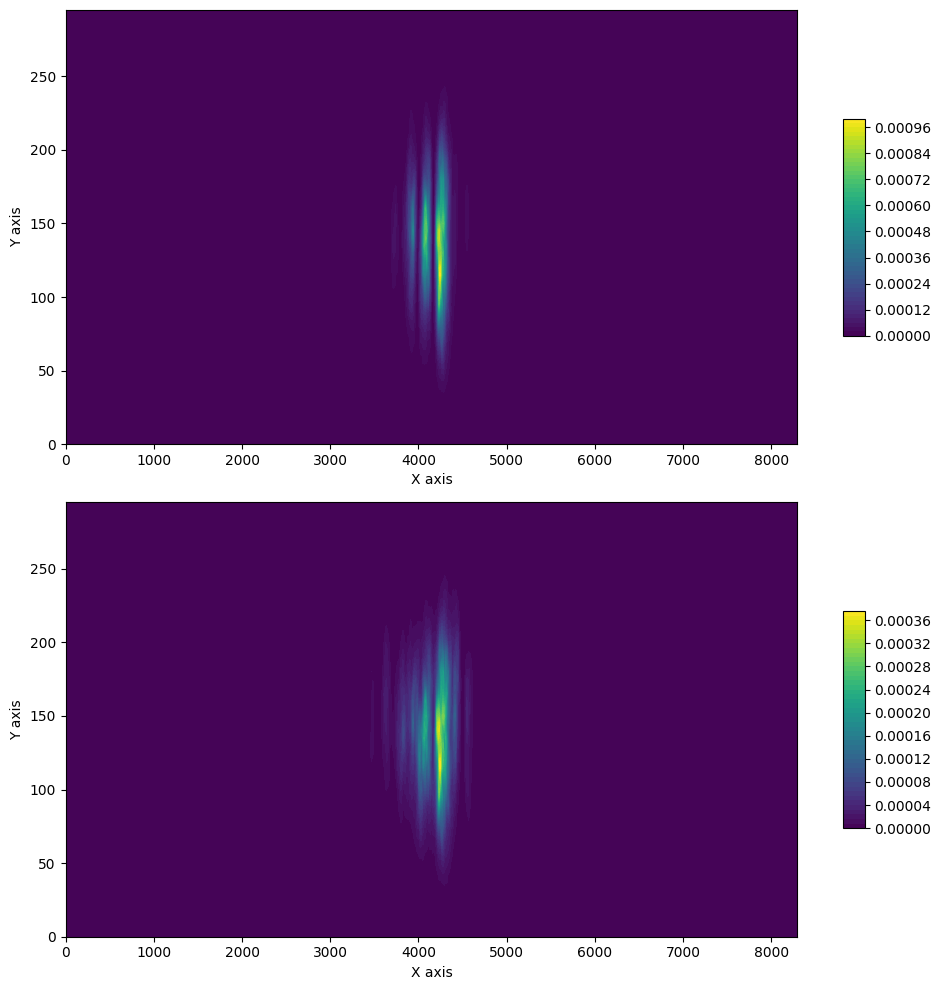

In [50]:
X = np.arange(NTOT)*AX

Y = np.arange(M)*AY

XM, YM = np.meshgrid(X,Y)

# Assuming XM and YM are meshgrids already created along with WV_ref_reshaped data
# You may need to redefine these or ensure they're available in your workspace

# Create a figure and a set of subplots in a 2x2 grid
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

# Iterate over each subplot and plot the specific data
i = 0

for ax in np.nditer(axes, flags=['refs_ok']):
    # Get the current axis from the iterator
    ax = ax.item()

    # Select the appropriate slice of the WV_ref_reshaped data
    Z = np.abs(GS_WV[i%2, :, :])**2

    # Generate contour plot for the selected data slice
    contourf = ax.contourf(XM, YM, Z, 50, cmap='viridis')  # Using 50 levels for the contour
    
    # Set titles and labels
    #ax.set_title(f'Contour Plot ')
    ax.set_xlabel('X axis')
    ax.set_ylabel('Y axis')

    # Add a color bar specific to each subplot
    fig.colorbar(contourf, ax=ax, shrink=0.5, aspect=10)

    # Increment the index for selecting data slices
    i += 1

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()

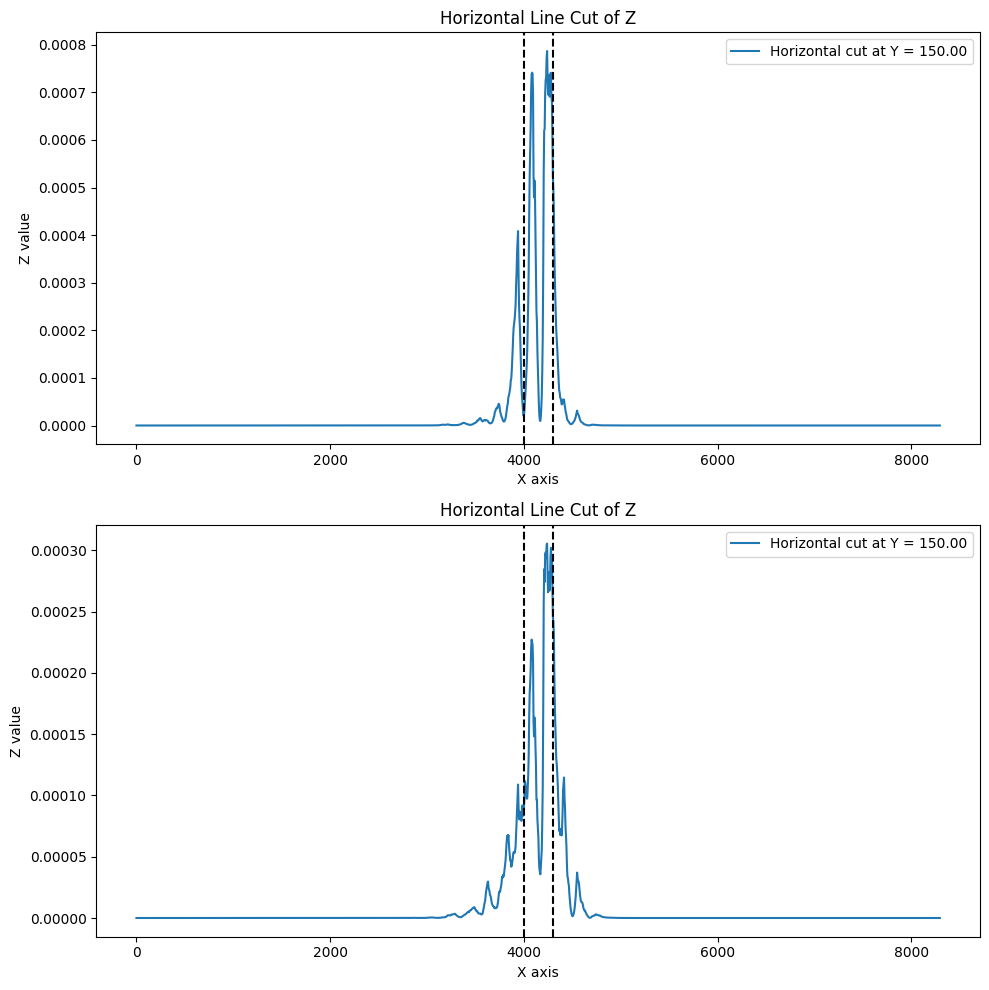

In [51]:
# Choose a specific index for the Y-axis
y_index = 30

# Create a figure and a set of subplots in a 2x2 grid
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

# Iterate over each subplot and plot the same data
i = 0 
for ax in axes.flatten():

    Z = np.abs(GS_WV[i%2,:,:])**2
    # Extract the Z values at this Y index
    Z_line_cut = Z[y_index, :]
    ax.plot(XM[0, :], Z_line_cut, label=f'Horizontal cut at Y = {YM[ y_index,0]:.2f}')
    ax.axvline(x=NSC*AX, color='black', linestyle='dashed')
    ax.axvline(x=(NSC+NSM)*AX, color='black', linestyle='dashed')
    ax.legend()
    ax.set_xlabel('X axis')
    ax.set_ylabel('Z value')
    ax.set_title('Horizontal Line Cut of Z')

    i+=1

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()

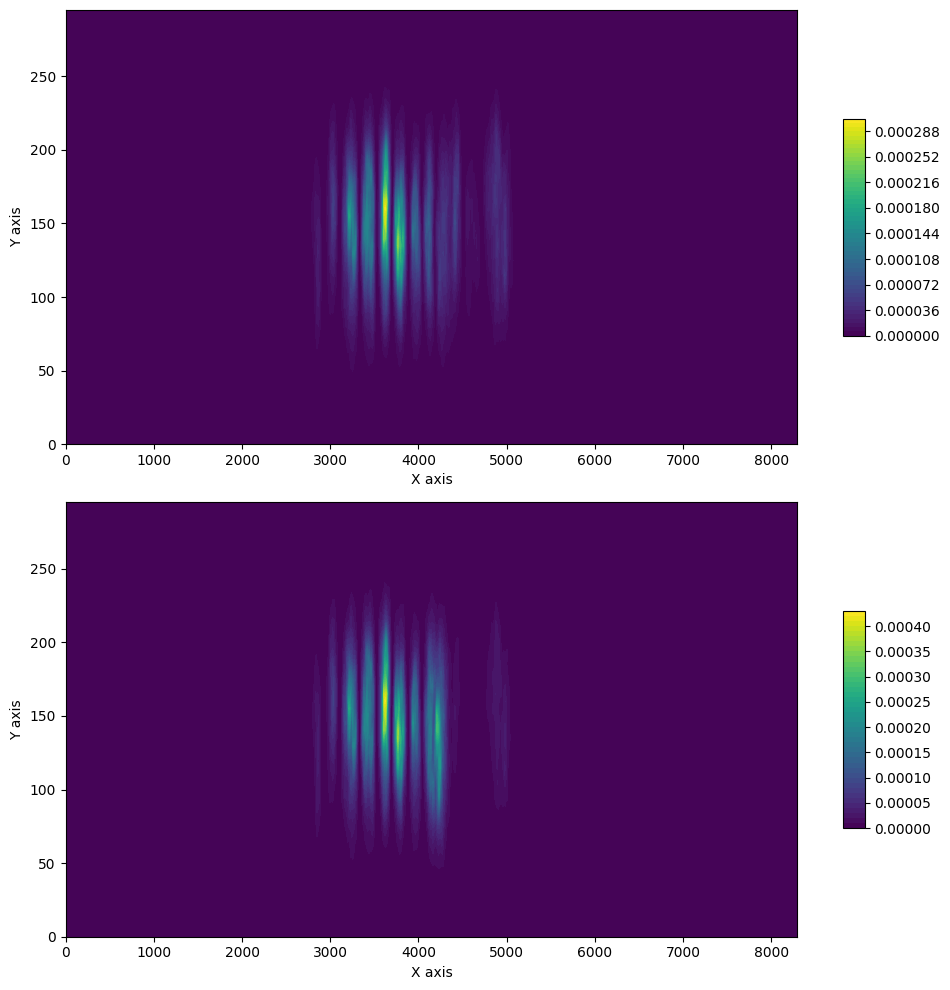

In [52]:
X = np.arange(NTOT)*AX

Y = np.arange(M)*AY

XM, YM = np.meshgrid(X,Y)

# Assuming XM and YM are meshgrids already created along with WV_ref_reshaped data
# You may need to redefine these or ensure they're available in your workspace

# Create a figure and a set of subplots in a 2x2 grid
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

# Iterate over each subplot and plot the specific data
i = 0

for ax in np.nditer(axes, flags=['refs_ok']):
    # Get the current axis from the iterator
    ax = ax.item()

    # Select the appropriate slice of the WV_ref_reshaped data
    Z = np.abs(ES_WV[i%2, :, :])**2

    # Generate contour plot for the selected data slice
    contourf = ax.contourf(XM, YM, Z, 50, cmap='viridis')  # Using 50 levels for the contour
    
    # Set titles and labels
    #ax.set_title(f'Contour Plot ')
    ax.set_xlabel('X axis')
    ax.set_ylabel('Y axis')

    # Add a color bar specific to each subplot
    fig.colorbar(contourf, ax=ax, shrink=0.5, aspect=10)

    # Increment the index for selecting data slices
    i += 1

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()

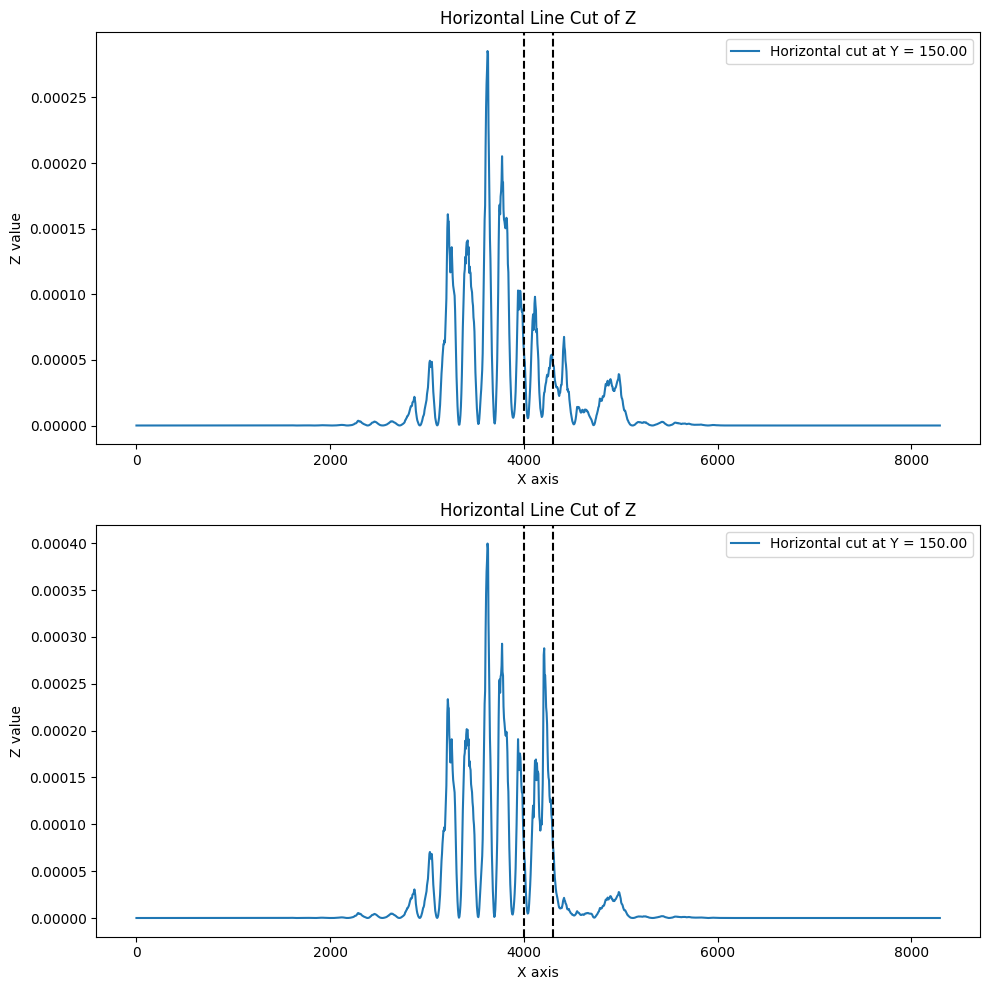

In [53]:
# Choose a specific index for the Y-axis
y_index = 30

# Create a figure and a set of subplots in a 2x2 grid
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

# Iterate over each subplot and plot the same data
i = 0 
for ax in axes.flatten():

    Z = np.abs(ES_WV[i%2,:,:])**2
    # Extract the Z values at this Y index
    Z_line_cut = Z[y_index, :]
    ax.plot(XM[0, :], Z_line_cut, label=f'Horizontal cut at Y = {YM[ y_index,0]:.2f}')
    ax.axvline(x=NSC*AX, color='black', linestyle='dashed')
    ax.axvline(x=(NSC+NSM)*AX, color='black', linestyle='dashed')
    ax.legend()
    ax.set_xlabel('X axis')
    ax.set_ylabel('Z value')
    ax.set_title('Horizontal Line Cut of Z')

    i+=1

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()